# LAB — Vision-Language Models: CLIP & LLaVA

**Module:** Artificial Intelligence / Generative AI  
**Level:** Phd Students  
**Environment:** Google Colab / Kaggle / Jupyter Notebook  
**Frameworks:** Python, PyTorch, Hugging Face Transformers

## Videos (Must see before Starting the Lab)
* https://www.youtube.com/watch?v=jXD6O93Ptks&t=6s
* https://www.youtube.com/watch?v=bK9ns4DkxQg&t=8s

## Objectives

This practical work introduces two important vision-language models:

- **CLIP**: image-text representation, similarity, zero-shot classification and image retrieval.
- **LLaVA**: multimodal image understanding and visual question answering.

At the end of the Lab, students should be able to:
1. Load a pretrained CLIP model.
2. Compare images and textual descriptions.
3. Perform zero-shot classification.
4. Evaluate classification accuracy.
5. Perform text-to-image retrieval.
6. Understand the architecture of LLaVA.
7. Run visual question answering.
8. Identify visual hallucinations.
9. Compare CLIP and LLaVA.
10. Build a small multimodal assistant.

> **Notebook organization:** Part I is the student statement. Part II contains the correction and reference implementations. Students should first complete the exercises without opening the correction section.

# Part I — LAB STATEMENT

## Exercise 1 — Installation and model loading

Install the required libraries and load `openai/clip-vit-base-patch32`.

### Questions

**Q1.** What is CLIP?  
**Q2.** What are its two main components?  
**Q3.** What is the role of `CLIPProcessor`?  
**Q4.** What is the role of `CLIPModel`?

In [1]:
# Run this cell first, then restart the kernel before the next cell.
# transformers 5.x calls torch.accelerator, which does not exist in PyTorch 2.5.
!pip install -q "transformers==4.57.3" torch torchvision pillow matplotlib pandas

In [3]:
import torch
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
from transformers import CLIPProcessor, CLIPModel

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

model = CLIPModel.from_pretrained(
    "openai/clip-vit-base-patch32",
    use_safetensors=True,
).to(device)
processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

Device: cpu


Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

## Exercise 2 — Load an image

Upload an image containing a recognizable object.

Examples: a cat, dog, car, horse, bird, airplane, person, etc.

### Questions

**Q5.** What is the size of the image?  
**Q6.** What type of data is stored in the PIL image object?

Image size: (1060, 706)
Image mode: RGB


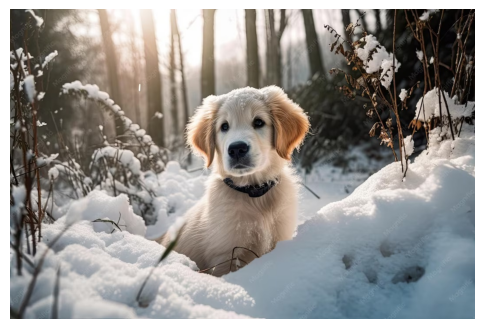

In [10]:
# Upload an image in Google Colab/Jupyter and change the filename if necessary.
IMAGE_PATH = "image.jpg"

image = Image.open(IMAGE_PATH).convert("RGB")
print("Image size:", image.size)
print("Image mode:", image.mode)

plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.axis("off");

## Exercise 3 — Image/Text similarity

Use the following textual descriptions:

```python
texts = [
    "a photo of a cat",
    "a photo of a dog",
    "a photo of a car",
    "a photo of a horse",
    "a photo of a person"
]
```

Calculate the CLIP image-text scores and convert them to probabilities.

### Questions

**Q7.** Which description has the highest probability?  
**Q8.** Is it compatible with the actual image?  
**Q9.** Why can CLIP compare an image with a sentence?  
**Q10.** What does `softmax()` do?

In [11]:
texts = [
    "a photo of a cat",
    "a photo of a dog",
    "a photo of a car",
    "a photo of a horse",
    "a photo of a person"
]

inputs = processor(
    text=texts,
    images=image,
    return_tensors="pt",
    padding=True
)
inputs = {k: v.to(device) for k, v in inputs.items()}

with torch.no_grad():
    outputs = model(**inputs)

probs = outputs.logits_per_image.softmax(dim=1)[0].cpu()

for text, probability in zip(texts, probs):
    print(f"{text:35s}: {probability.item():.4f}")

a photo of a cat                   : 0.0030
a photo of a dog                   : 0.9903
a photo of a car                   : 0.0001
a photo of a horse                 : 0.0039
a photo of a person                : 0.0027


## Exercise 4 — Zero-shot classification

Implement:

```python
def classify_image(image, classes):
    ...
```

The function must return the predicted class and its probability.

### Questions

**Q11.** What is zero-shot classification?  
**Q12.** Why is it not necessary to train a new classifier?  
**Q13.** What happens if the correct class is not included in the candidate classes?

In [12]:
def classify_image(image, classes):
    texts = [f"a photo of a {label}" for label in classes]
    inputs = processor(
        text=texts,
        images=image,
        return_tensors="pt",
        padding=True,
    )
    inputs = {k: v.to(device) for k, v in inputs.items()}

    with torch.no_grad():
        outputs = model(**inputs)

    probabilities = outputs.logits_per_image.softmax(dim=1)[0].cpu()
    best = int(probabilities.argmax())
    return classes[best], probabilities[best].item()


classes = ["cat", "dog", "car", "airplane", "horse", "bird"]

prediction, probability = classify_image(image, classes)
print("Prediction:", prediction)
print("Probability:", probability)

Prediction: dog
Probability: 0.9920525550842285


## Exercise 5 — Evaluate CLIP

Prepare at least 10 labeled images. For each image record:

- actual class;
- predicted class;
- probability;
- whether the prediction is correct.

Calculate:


$Accuracy = \frac{N_{correct}}{N_{total}}$


### Questions

**Q14.** What is the obtained accuracy?  
**Q15.** Which images are incorrectly classified?  
**Q16.** Give at least two possible reasons for the errors.

Use the following format:

```python
dataset = [
    ("cat1.jpg", "cat"),
    ("cat2.jpg", "cat"),
    ...
]
```

In [15]:
dataset = [
    ("data_ex5/cat1.png", "cat"),
    ("data_ex5/cat2.png", "cat"),
    ("data_ex5/dog1.jpg", "dog"),
    ("data_ex5/airplane1.png", "airplane"),
    ("data_ex5/horse1.png", "horse"),
    ("data_ex5/bird1.png", "bird"),
    ("data_ex5/bird2.png", "bird"),
]

rows = []
for path, actual in dataset:
    sample = Image.open(path).convert("RGB")
    predicted, probability = classify_image(sample, classes)
    rows.append({
        "image": path,
        "actual": actual,
        "predicted": predicted,
        "probability": round(probability, 4),
        "correct": predicted == actual,
    })

results = pd.DataFrame(rows)
n_correct = int(results["correct"].sum())
n_total = len(results)
accuracy = n_correct / n_total

print(results.to_string(index=False))
print(f"Accuracy: {accuracy:.2f} ({n_correct}/{n_total})")
print("Incorrect images:")
print(results.loc[~results["correct"], ["image", "actual", "predicted"]].to_string(index=False))

                 image   actual predicted  probability  correct
     data_ex5/cat1.png      cat       cat       0.9959     True
     data_ex5/cat2.png      cat       cat       0.9920     True
     data_ex5/dog1.jpg      dog       dog       0.9921     True
data_ex5/airplane1.png airplane  airplane       0.9962     True
   data_ex5/horse1.png    horse     horse       0.9993     True
    data_ex5/bird1.png     bird      bird       0.9982     True
    data_ex5/bird2.png     bird      bird       0.9975     True
Accuracy: 1.00 (7/7)
Incorrect images:
Empty DataFrame
Columns: [image, actual, predicted]
Index: []


Q16 : Deux causes d'erreur possibles, même si elles n'apparaissent pas ici : la bonne classe est absente des candidats, donc CLIP doit en choisir une autre ; l'image est ambiguë ou le prompt « a photo of a … » correspond mal au contenu (dessin, cadrage inhabituel, classes visuellement proches).

## Exercise 6 — Prompt engineering with CLIP

Compare:

```python
prompts = [
    "a cat",
    "a photo of a cat",
    "a photograph showing a cat",
    "an image containing a cat",
    "a domestic animal called a cat"
]
```

### Questions

**Q17.** Are the scores identical?  
**Q18.** Which prompt gives the highest score?  
**Q19.** What does this demonstrate about prompt formulation?

In [16]:
prompts = [
    "a cat",
    "a photo of a cat",
    "a photograph showing a cat",
    "an image containing a cat",
    "a domestic animal called a cat",
]

inputs = processor(
    text=prompts,
    images=image,
    return_tensors="pt",
    padding=True,
)
inputs = {k: v.to(device) for k, v in inputs.items()}

with torch.no_grad():
    outputs = model(**inputs)

scores = outputs.logits_per_image.softmax(dim=1)[0].cpu()

for prompt, score in sorted(zip(prompts, scores), key=lambda item: item[1], reverse=True):
    print(f"{score.item():.4f}  {prompt}")

0.4762  a photo of a cat
0.2165  a domestic animal called a cat
0.1984  an image containing a cat
0.0805  a cat
0.0285  a photograph showing a cat


# Part B — CLIP Image Retrieval

## Exercise 7 — Build an image database

Create a folder containing at least 20 images.

The images can represent animals, vehicles, people, buildings, landscapes, food or sports.

Calculate and store a normalized CLIP embedding for every image.

## Exercise 8 — Text-to-image retrieval

Use the query:

```text
"a person playing football"
```

Calculate its text embedding, compare it with all image embeddings, and display the five most similar images.

### Questions

**Q20.** What is the most similar image?  
**Q21.** Is it semantically relevant?  
**Q22.** Why does this method not require image labels?  
**Q23.** Give one real-world application of semantic image retrieval.

Database size: 21 images
Query: a person playing football

1. football1.jpg         cosine=0.2828
2. football3.jpg         cosine=0.2697
3. football2.jpg         cosine=0.2477
4. tennis.jpg            cosine=0.2390
5. basketball.jpg        cosine=0.2021


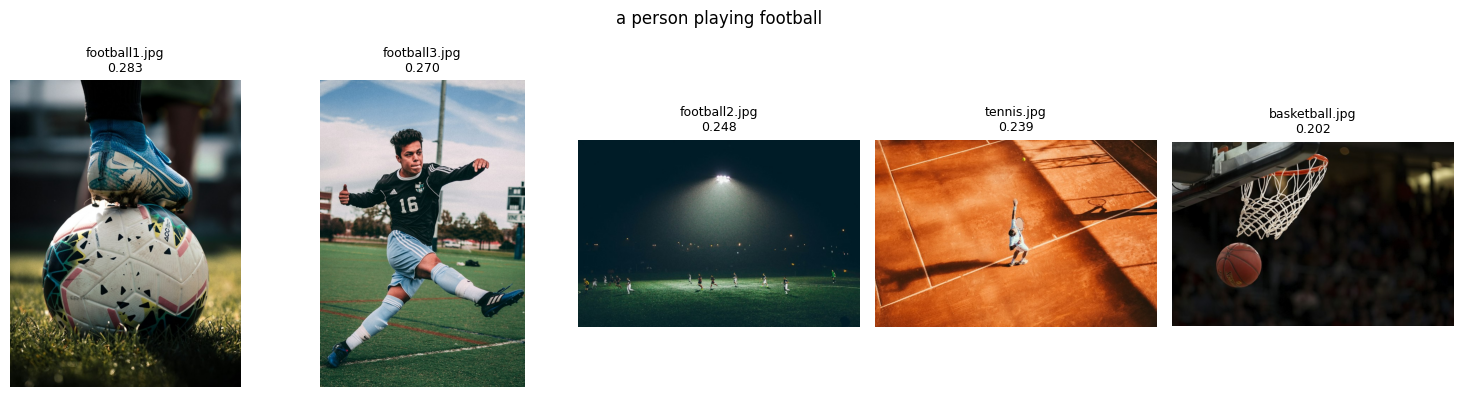

In [17]:
from pathlib import Path

IMAGE_DIR = "images"
QUERY = "a person playing football"
TOP_K = 5

image_paths = sorted(
    path for path in Path(IMAGE_DIR).iterdir()
    if path.suffix.lower() in {".jpg", ".jpeg", ".png"}
)
print(f"Database size: {len(image_paths)} images")

pil_images = [Image.open(path).convert("RGB") for path in image_paths]
image_inputs = processor(images=pil_images, return_tensors="pt", padding=True)
image_inputs = {k: v.to(device) for k, v in image_inputs.items()}
text_inputs = processor(text=[QUERY], return_tensors="pt", padding=True)
text_inputs = {k: v.to(device) for k, v in text_inputs.items()}

with torch.no_grad():
    image_embeddings = model.get_image_features(**image_inputs)
    text_embedding = model.get_text_features(**text_inputs)

image_embeddings = torch.nn.functional.normalize(image_embeddings, dim=-1)
text_embedding = torch.nn.functional.normalize(text_embedding, dim=-1)
similarities = (image_embeddings @ text_embedding.T).squeeze(-1).cpu()

top_k = similarities.topk(k=min(TOP_K, len(image_paths)))
print(f"Query: {QUERY}\n")
for rank, (index, score) in enumerate(zip(top_k.indices, top_k.values), start=1):
    print(f"{rank}. {image_paths[int(index)].name:20s}  cosine={score.item():.4f}")

fig, axes = plt.subplots(1, TOP_K, figsize=(15, 4))
for ax, index, score in zip(axes, top_k.indices, top_k.values):
    path = image_paths[int(index)]
    ax.imshow(Image.open(path).convert("RGB"))
    ax.set_title(f"{path.name}\n{score.item():.3f}", fontsize=9)
    ax.axis("off")
plt.suptitle(QUERY)
plt.tight_layout()

 Q20 : L’image la plus similaire est football1.jpg (pied avec crampon posé sur un ballon de football).
 
 Q21. Oui : le contenu est bien lié au football, même si le cadrage montre surtout le ballon et la chaussure plutôt qu’un match entier.

 Q22. CLIP place images et textes dans le même espace. On compare des vecteurs, sans avoir besoin de noms de fichiers ni d’étiquettes.

 Q23. Une application : moteur de recherche d’une photothèque (banque d’images, archives médias) à partir d’une phrase, sans index manuel.


# Part C — LLaVA

## Exercise 9 — Architecture

Complete:

```text
Image
  |
  v
CLIP Vision Encoder
  |
  v
______________
  |
  v
Language Model
  |
  v
Text Response
```

### Questions

**Q24.** What is the role of the vision encoder?  
**Q25.** Why is a projection layer required?  
**Q26.** What is the role of the language model?

Q24 : The vision encoder extracts visual features from the input image, such as objects, shapes, and visual patterns. LLaVA uses the CLIP Vision Encoder to transform the image into numerical representations (embeddings).

Q25 : The projection layer converts the visual features into a representation compatible with the language model's embedding space. This allows the language model to understand and use visual information when generating a response.

Q26 : The language model combines the visual information with the user's text prompt to understand the question and generate a relevant natural-language response.

## Exercise 10 — Run LLaVA

Use a LLaVA-compatible model appropriate for your available GPU.

Give the model an image and ask:

1. What is happening in this image?
2. How many people are visible?
3. What objects can you identify?
4. Describe the image in detail.

Record the answers.

In [18]:
from transformers import AutoProcessor, LlavaOnevisionForConditionalGeneration

# This machine has no CUDA GPU. LLaVA-OneVision 0.5B is a LLaVA-family
# checkpoint small enough to run on CPU. On a larger GPU, replace with
# "llava-hf/llava-1.5-7b-hf" and LlavaForConditionalGeneration.
MODEL_ID = "llava-hf/llava-onevision-qwen2-0.5b-ov-hf"
dtype = torch.float16 if device == "cuda" else torch.float32

processor_llava = AutoProcessor.from_pretrained(MODEL_ID)
llava = LlavaOnevisionForConditionalGeneration.from_pretrained(
    MODEL_ID,
    torch_dtype=dtype,
    low_cpu_mem_usage=True,
)
llava = llava.to(device)
llava.eval()

def ask_llava(image, question, max_new_tokens=80):
    conversation = [
        {
            "role": "user",
            "content": [
                {"type": "image"},
                {"type": "text", "text": question},
            ],
        }
    ]
    prompt = processor_llava.apply_chat_template(
        conversation, add_generation_prompt=True
    )
    inputs = processor_llava(text=prompt, images=image, return_tensors="pt")
    inputs = {
        key: value.to(device=device, dtype=dtype) if value.is_floating_point() else value.to(device)
        for key, value in inputs.items()
    }
    with torch.no_grad():
        output_ids = llava.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
        )
    decoded = processor_llava.batch_decode(output_ids, skip_special_tokens=True)[0]
    return decoded.split("assistant")[-1].strip()

questions = [
    "What is happening in this image?",
    "How many people are visible?",
    "What objects can you identify?",
    "Describe the image in detail.",
]

llava_answers = {}
for question in questions:
    answer = ask_llava(image, question)
    llava_answers[question] = answer
    print("Q:", question)
    print("A:", answer)
    print()

'(MaxRetryError('HTTPSConnectionPool(host=\'huggingface.co\', port=443): Max retries exceeded with url: /llava-hf/llava-onevision-qwen2-0.5b-ov-hf/resolve/main/processor_config.json (Caused by NameResolutionError("HTTPSConnection(host=\'huggingface.co\', port=443): Failed to resolve \'huggingface.co\' ([Errno 11001] getaddrinfo failed)"))'), '(Request ID: 1cb24c23-f381-484b-8d7a-0cc5db4ddd04)')' thrown while requesting HEAD https://huggingface.co/llava-hf/llava-onevision-qwen2-0.5b-ov-hf/resolve/main/processor_config.json
Retrying in 1s [Retry 1/5].
'(MaxRetryError('HTTPSConnectionPool(host=\'huggingface.co\', port=443): Max retries exceeded with url: /llava-hf/llava-onevision-qwen2-0.5b-ov-hf/resolve/main/processor_config.json (Caused by NameResolutionError("HTTPSConnection(host=\'huggingface.co\', port=443): Failed to resolve \'huggingface.co\' ([Errno 11001] getaddrinfo failed)"))'), '(Request ID: 6f302017-efb4-4dfb-b400-23591c36d261)')' thrown while requesting HEAD https://huggingf

model.safetensors:   0%|          | 0.00/1.79G [00:00<?, ?B/s]

Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.


Q: What is happening in this image?
A: A golden retriever puppy is sitting in the snow.



Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.


Q: How many people are visible?
A: There are no people visible in the image. The focus is solely on the dog in the snowy forest setting.



Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.


Q: What objects can you identify?
A: In the image, there is a golden retriever puppy sitting in the snow. The puppy has a fluffy coat and is wearing a collar. The background consists of snow-covered trees and bushes, with sunlight filtering through the trees, creating a warm and serene atmosphere.

Q: Describe the image in detail.
A: The image captures a serene winter scene featuring a golden retriever puppy nestled in a snowy forest. The puppy, with its light golden fur, is the central focus of the image. It is wearing a black collar, adding a touch of contrast to its appearance. The puppy is sitting in the snow, its body partially covered by the white blanket of snow, giving it a cozy and adorable look.

The



**Recorded LLaVA answers** (image: `image.jpg`, model: `llava-hf/llava-onevision-qwen2-0.5b-ov-hf`)

1. **What is happening in this image?**  
   A golden retriever puppy is sitting in the snow.

2. **How many people are visible?**  
   There are no people visible in the image. The focus is solely on the dog in the snowy forest setting.

3. **What objects can you identify?**  
   In the image, there is a golden retriever puppy sitting in the snow. The puppy has a fluffy coat and is wearing a collar. The background consists of snow-covered trees and bushes, with sunlight filtering through the trees, creating a warm and serene atmosphere.

4. **Describe the image in detail.**  
   The image captures a serene winter scene featuring a golden retriever puppy nestled in a snowy forest. The puppy, with its light golden fur, is the central focus of the image. It is wearing a black collar, adding a touch of contrast to its appearance. The puppy is sitting in the snow, its body partially covered by the white blanket of snow, giving it a cozy and adorable look.

## Exercise 11 — Visual Question Answering

Choose five images. For each image ask five questions.

Example:

1. How many people are visible?
2. What objects can you see?
3. Where are the people?
4. What are they doing?
5. What is visible on the board?

Create a table containing:

| Image | Question | LLaVA Answer | Human Evaluation |
|---|---|---|---|

Calculate VQA accuracy:

\[
Accuracy = \frac{CorrectAnswers}{TotalQuestions}
\]

### Questions

**Q27.** What is the VQA accuracy?  
**Q28.** Which types of questions are difficult for LLaVA?

In [20]:
vqa_set = [
    (
        "image.jpg",
        [
            "How many people are visible?",
            "What animal is in the image?",
            "Where is the dog?",
            "What is the weather like?",
            "What color is the collar?",
        ],
    ),
    (
        "data_ex5/cat1.png",
        [
            "How many cats are visible?",
            "What objects can you see?",
            "What color are the cat's eyes?",
            "Where is the cat sitting?",
            "What is the cat doing?",
        ],
    ),
    (
        "data_ex5/airplane1.png",
        [
            "How many airplanes are visible?",
            "What objects can you see?",
            "What is the airplane doing?",
            "What color is the sky?",
            "Which airline is this?",
        ],
    ),
    (
        "images/football1.jpg",
        [
            "How many people are fully visible?",
            "What objects can you see?",
            "Where is the player's foot?",
            "What is happening in this image?",
            "What color is the football boot?",
        ],
    ),
    (
        "images/person.jpg",
        [
            "How many people are visible?",
            "What is the person wearing?",
            "What is the person doing?",
            "What color is the hair?",
            "What is visible on the board?",
        ],
    ),
]

vqa_rows = []
for path, questions in vqa_set:
    sample = Image.open(path).convert("RGB")
    sample.thumbnail((384, 384))
    for question in questions:
        answer = ask_llava(sample, question, max_new_tokens=60)
        vqa_rows.append({
            "image": path,
            "question": question,
            "llava_answer": answer,
        })
        print(path, "|", question)
        print(answer)
        print()

vqa_df = pd.DataFrame(vqa_rows)
vqa_df

Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.


image.jpg | How many people are visible?
There are no people visible in the image. The image shows a dog in a snowy environment.



Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.


image.jpg | What animal is in the image?
A dog.



Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.


...

Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.


images/person.jpg | What is the person doing?
The person is posing for the camera.



Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.


images/person.jpg | What color is the hair?
The hair color is blonde.

images/person.jpg | What is visible on the board?
The image does not show a board. It appears to be a photograph of a person, but the content of the photograph is not visible.



,image,question,llava_answer
0,image.jpg,How many people are visible?,There are no people visible in the image. The ...
1,image.jpg,What animal is in the image?,A dog.
2,image.jpg,Where is the dog?,The dog is in a snowy forest.
3,image.jpg,What is the weather like?,"The weather appears to be cold and snowy, as i..."
4,image.jpg,What color is the collar?,The collar is black.
5,data_ex5/cat1.png,How many cats are visible?,There is one cat visible in the image. It is a...
6,data_ex5/cat1.png,What objects can you see?,"In the image, there is a fluffy white cat with..."
7,data_ex5/cat1.png,What color are the cat's eyes?,The cat's eyes are blue.
8,data_ex5/cat1.png,Where is the cat sitting?,The cat is sitting on a table.
9,data_ex5/cat1.png,What is the cat doing?,The cat is lying down on a surface.


**VQA results** (25 questions, model: `llava-hf/llava-onevision-qwen2-0.5b-ov-hf`)

| Image | Question | LLaVA Answer | Human Evaluation |
|---|---|---|---|
| image.jpg | How many people are visible? | There are no people visible. The image shows a dog in a snowy environment. | Correct |
| image.jpg | What animal is in the image? | A dog. | Correct |
| image.jpg | Where is the dog? | The dog is in a snowy forest. | Correct |
| image.jpg | What is the weather like? | Cold and snowy. | Correct |
| image.jpg | What color is the collar? | Black. | Correct |
| data_ex5/cat1.png | How many cats are visible? | One cat. | Correct |
| data_ex5/cat1.png | What objects can you see? | A fluffy white cat with blue eyes, a wicker basket, and a plant. | Correct |
| data_ex5/cat1.png | What color are the cat's eyes? | Blue. | Correct |
| data_ex5/cat1.png | Where is the cat sitting? | On a table. | Correct |
| data_ex5/cat1.png | What is the cat doing? | Lying down on a surface. | Correct |
| data_ex5/airplane1.png | How many airplanes are visible? | One airplane. | Correct |
| data_ex5/airplane1.png | What objects can you see? | A commercial airplane in the sky, white with blue accents and a Delta tail logo. | Correct |
| data_ex5/airplane1.png | What is the airplane doing? | Flying. | Correct |
| data_ex5/airplane1.png | What color is the sky? | Blue. | Correct |
| data_ex5/airplane1.png | Which airline is this? | Delta. | Correct |
| images/football1.jpg | How many people are fully visible? | One person, with their leg and foot in focus. | Incorrect |
| images/football1.jpg | What objects can you see? | A patterned soccer ball, a blue/white cleat, outdoor field. | Correct |
| images/football1.jpg | Where is the player's foot? | On top of the soccer ball. | Correct |
| images/football1.jpg | What is happening in this image? | The player has just kicked the ball (ball in motion). | Incorrect |
| images/football1.jpg | What color is the football boot? | Blue. | Correct |
| images/person.jpg | How many people are visible? | One person. | Correct |
| images/person.jpg | What is the person wearing? | A black sheer top with a lace-like texture. | Correct |
| images/person.jpg | What is the person doing? | Posing for the camera. | Correct |
| images/person.jpg | What color is the hair? | Blonde. | Correct |
| images/person.jpg | What is visible on the board? | There is no board in the image. | Correct |

$$Accuracy = 23/25 = 0.92$$

**Q27.** The VQA accuracy is **0.92** (23 correct answers out of 25).

**Q28.** The hardest questions were **fine-grained counting** ("fully visible" people when only a foot is shown) and **precise action recognition** (the boot is resting on the ball, but LLaVA described a kick in motion). Open-ended object lists and yes/no absence questions were easier.

## Exercise 12 — Hallucination

Choose an image that does **not** contain a bicycle.

Ask:

> Is there a bicycle in this image?

Then ask:

> What color is the bicycle?

Then ask:

> Where is the bicycle located?

### Questions

**Q29.** Does the bicycle actually exist?  
**Q30.** Did LLaVA invent information?  
**Q31.** What is a visual hallucination?  
**Q32.** Why can a multimodal model hallucinate?

In [5]:
from PIL import Image
import torch

if "ask_llava" not in globals():
    from transformers import AutoProcessor, LlavaOnevisionForConditionalGeneration

    device = "cuda" if torch.cuda.is_available() else "cpu"
    dtype = torch.float16 if device == "cuda" else torch.float32
    MODEL_ID = "llava-hf/llava-onevision-qwen2-0.5b-ov-hf"
    processor_llava = AutoProcessor.from_pretrained(MODEL_ID)
    llava = LlavaOnevisionForConditionalGeneration.from_pretrained(
        MODEL_ID,
        torch_dtype=dtype,
        low_cpu_mem_usage=True,
    ).to(device)
    llava.eval()

    def ask_llava(image, question, max_new_tokens=80):
        conversation = [
            {
                "role": "user",
                "content": [
                    {"type": "image"},
                    {"type": "text", "text": question},
                ],
            }
        ]
        prompt = processor_llava.apply_chat_template(
            conversation, add_generation_prompt=True
        )
        inputs = processor_llava(text=prompt, images=image, return_tensors="pt")
        inputs = {
            key: value.to(device=device, dtype=dtype) if value.is_floating_point() else value.to(device)
            for key, value in inputs.items()
        }
        with torch.no_grad():
            output_ids = llava.generate(
                **inputs,
                max_new_tokens=max_new_tokens,
                do_sample=False,
            )
        decoded = processor_llava.batch_decode(output_ids, skip_special_tokens=True)[0]
        return decoded.split("assistant")[-1].strip()

HALLUCINATION_IMAGE = "image.jpg"  # no bicycle in this photo
hallucination_image = Image.open(HALLUCINATION_IMAGE).convert("RGB")
hallucination_image.thumbnail((384, 384))

hallucination_questions = [
    "Is there a bicycle in this image?",
    "What color is the bicycle?",
    "Where is the bicycle located?",
]

print("Image:", HALLUCINATION_IMAGE)
for question in hallucination_questions:
    answer = ask_llava(hallucination_image, question, max_new_tokens=60)
    print("Q:", question)
    print("A:", answer)
    print()

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.
`torch_dtype` is deprecated! Use `dtype` instead!


Image: image.jpg


Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.


Q: Is there a bicycle in this image?
A: no



Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.


Q: Where is the bicycle located?
A: The bicycle is located in the middle of the image, surrounded by snow-covered ground and trees.



**Hallucination test** (image: `image.jpg`, a dog in the snow, no bicycle)

| Question | LLaVA answer |
|---|---|
| Is there a bicycle in this image? | no |
| What color is the bicycle? | The bicycle in the image is not visible. |
| Where is the bicycle located? | The bicycle is located in the middle of the image, surrounded by snow-covered ground and trees. |

**Q29.** No. There is no bicycle in the image; it shows a golden retriever in the snow.

**Q30.** Yes, on the follow-up questions. LLaVA first correctly said there was no bicycle, then treated the bicycle as an object that is merely "not visible", and finally invented a precise location in the snow.

**Q31.** A visual hallucination is a generated statement about objects, attributes or locations that are **not present in the image**.

**Q32.** Multimodal models can hallucinate because the language model is trained to produce fluent, complete answers. If a later question **assumes** that an object exists, the text decoder may follow that assumption even when the visual features do not support it. Vision and language are aligned imperfectly, and the model has no strict grounding check.

# Part D — CLIP vs LLaVA

## Exercise 13 — Comparative experiment

Use the same image with both models.

### CLIP

Compare:

- a photo of a cat
- a photo of a dog
- a photo of a horse

### LLaVA

Ask:

> What animal is present in the image? Describe its appearance.

Complete:

| Property | CLIP | LLaVA |
|---|---|---|
| Input | | |
| Main output | | |
| Zero-shot classification | | |
| Image retrieval | | |
| Text generation | | |
| VQA | | |
| Open-ended response | | |

### Questions

**Q33.** Which model is better suited to image classification?  
**Q34.** Which model is better for image description?  
**Q35.** Which model is better for visual question answering?  
**Q36.** Explain the fundamental difference between CLIP and LLaVA.

In [6]:
from PIL import Image
import torch
from transformers import CLIPModel, CLIPProcessor

COMPARE_IMAGE = "image.jpg"
compare_image = Image.open(COMPARE_IMAGE).convert("RGB")

if "model" not in globals() or "processor" not in globals():
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model = CLIPModel.from_pretrained(
        "openai/clip-vit-base-patch32",
        use_safetensors=True,
    ).to(device)
    processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

clip_texts = [
    "a photo of a cat",
    "a photo of a dog",
    "a photo of a horse",
]
clip_inputs = processor(
    text=clip_texts,
    images=compare_image,
    return_tensors="pt",
    padding=True,
)
clip_inputs = {k: v.to(device) for k, v in clip_inputs.items()}
with torch.no_grad():
    clip_outputs = model(**clip_inputs)
clip_probs = clip_outputs.logits_per_image.softmax(dim=1)[0].cpu()

print("CLIP zero-shot scores")
for text, probability in zip(clip_texts, clip_probs):
    print(f"{text:22s}: {probability.item():.4f}")
print("CLIP prediction:", clip_texts[int(clip_probs.argmax())])

llava_prompt = "What animal is present in the image? Describe its appearance."
if "ask_llava" in globals():
    llava_image = compare_image.copy()
    llava_image.thumbnail((384, 384))
    llava_description = ask_llava(llava_image, llava_prompt, max_new_tokens=80)
    print("\nLLaVA")
    print("Q:", llava_prompt)
    print("A:", llava_description)
else:
    print("\nRun the LLaVA cell first, then re-run this comparison.")

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


CLIP zero-shot scores
a photo of a cat      : 0.0030
a photo of a dog      : 0.9932
a photo of a horse    : 0.0039
CLIP prediction: a photo of a dog


Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.



LLaVA
Q: What animal is present in the image? Describe its appearance.
A: A golden retriever puppy is present in the image. It has a light golden coat and floppy ears.


**Same image:** `image.jpg`

**CLIP scores**

- a photo of a cat: **0.0030**
- a photo of a dog: **0.9932**
- a photo of a horse: **0.0039**

CLIP prediction: **a photo of a dog**

**LLaVA**

> What animal is present in the image? Describe its appearance.

A golden retriever puppy is present in the image. It has a light golden coat and floppy ears.

| Property | CLIP | LLaVA |
|---|---|---|
| Input | Image + candidate texts | Image + natural-language question |
| Main output | Similarity scores / probabilities | Generated text |
| Zero-shot classification | Yes, by scoring class prompts | Indirectly, via a question |
| Image retrieval | Yes, with embeddings and cosine similarity | No, not designed for retrieval |
| Text generation | No | Yes |
| VQA | No | Yes |
| Open-ended response | No | Yes |

**Q33.** CLIP is better suited to image classification: it ranks a closed set of labels with calibrated scores (here 0.9932 for dog).

**Q34.** LLaVA is better for image description: it generates an open sentence (golden retriever puppy, light coat, floppy ears), which CLIP cannot do.

**Q35.** LLaVA is better for visual question answering, because it answers free-form questions instead of only comparing fixed captions.

**Q36.** CLIP maps images and texts into a **shared embedding space** and measures similarity. LLaVA connects a **vision encoder** to a **language model** so it can generate answers from visual tokens. CLIP matches; LLaVA explains.

# Final Mini-Project

Develop a small **Multimodal Image Assistant**.

The application receives:

```text
Image + Question
```

and returns an answer.

### Basic architecture

```text
             IMAGE
               |
               v
        +--------------+
        | Vision Model |
        +------+-------+
               |
               v
        Visual Features
               |
               v
QUESTION ---> LLaVA
               |
               v
             ANSWER
```

### Bonus

Combine CLIP retrieval with LLaVA:

```text
User Query
    |
    v
   CLIP
    |
    v
Top-K Images
    |
    v
  LLaVA
    |
    v
Explanation
```

### Deliverables

1. Jupyter Notebook.
2. Code and outputs for every experiment.
3. CLIP classification accuracy.
4. Top-5 retrieval results.
5. LLaVA VQA results.
6. At least one hallucination example.
7. CLIP/LLaVA comparison.
8. Mini-project.
9. Short conclusion.

=== Assistant: dedicated image + question ===


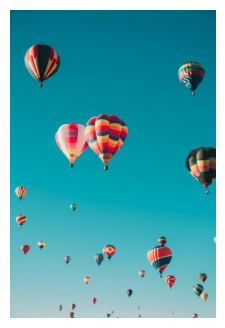

Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.


Image: mini_project.jpg
In the image, there is a vibrant scene of numerous hot air balloons floating in the sky. The balloons are of various sizes and colors, creating a visually striking contrast against the clear blue sky. Some balloons are closer to the viewer, appearing larger and more detailed, while others are further away, appearing smaller and less distinct. The balloons are scattered across the sky, some floating higher and others lower,

=== Bonus: CLIP retrieval + LLaVA explanation ===
(This part still uses the images/ database from Exercise 7.)


Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.


football1.jpg  cosine=0.2828
The image shows a person's foot on a soccer ball, which is a common scene in a soccer game. The person is wearing a blue soccer cleat, which is appropriate footwear for the sport. The focus is on the ball and the foot, with the background being out of focus, emphasizing the action of the person playing. The image does not match the query 'a person playing football,' as


In [10]:
from pathlib import Path
from PIL import Image
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from transformers import CLIPModel, CLIPProcessor

def ensure_clip():
    global device, model, processor
    if "model" in globals() and "processor" in globals():
        return model, processor
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model = CLIPModel.from_pretrained(
        "openai/clip-vit-base-patch32",
        use_safetensors=True,
    ).to(device)
    processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
    return model, processor

def ensure_llava():
    global ask_llava, device
    if "ask_llava" in globals():
        return ask_llava
    from transformers import AutoProcessor, LlavaOnevisionForConditionalGeneration
    device = "cuda" if torch.cuda.is_available() else "cpu"
    dtype = torch.float16 if device == "cuda" else torch.float32
    model_id = "llava-hf/llava-onevision-qwen2-0.5b-ov-hf"
    processor_llava = AutoProcessor.from_pretrained(model_id)
    llava = LlavaOnevisionForConditionalGeneration.from_pretrained(
        model_id, torch_dtype=dtype, low_cpu_mem_usage=True
    ).to(device)
    llava.eval()

    def ask_llava(image, question, max_new_tokens=80):
        conversation = [{
            "role": "user",
            "content": [{"type": "image"}, {"type": "text", "text": question}],
        }]
        prompt = processor_llava.apply_chat_template(conversation, add_generation_prompt=True)
        inputs = processor_llava(text=prompt, images=image, return_tensors="pt")
        inputs = {
            key: value.to(device=device, dtype=dtype) if value.is_floating_point() else value.to(device)
            for key, value in inputs.items()
        }
        with torch.no_grad():
            output_ids = llava.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
        decoded = processor_llava.batch_decode(output_ids, skip_special_tokens=True)[0]
        return decoded.split("assistant")[-1].strip()

    return ask_llava

def multimodal_assistant(image, question, max_new_tokens=80):
    """Image + question -> natural-language answer (LLaVA)."""
    ask = ensure_llava()
    if isinstance(image, (str, Path)):
        image = Image.open(image).convert("RGB")
    else:
        image = image.convert("RGB")
    vis = image.copy()
    vis.thumbnail((384, 384))
    return ask(vis, question, max_new_tokens=max_new_tokens)

def retrieve_and_explain(query, image_dir="images", k=1):
    """Bonus: CLIP retrieves Top-K images, LLaVA explains the best match."""
    clip_model, clip_processor = ensure_clip()
    paths = sorted(
        p for p in Path(image_dir).iterdir()
        if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
    )
    pil_images = [Image.open(p).convert("RGB") for p in paths]
    image_inputs = clip_processor(images=pil_images, return_tensors="pt", padding=True)
    image_inputs = {key: value.to(device) for key, value in image_inputs.items()}
    text_inputs = clip_processor(text=[query], return_tensors="pt", padding=True)
    text_inputs = {key: value.to(device) for key, value in text_inputs.items()}
    with torch.no_grad():
        image_emb = F.normalize(clip_model.get_image_features(**image_inputs), dim=-1)
        text_emb = F.normalize(clip_model.get_text_features(**text_inputs), dim=-1)
    scores = (image_emb @ text_emb.T).squeeze(-1).cpu()
    top = scores.topk(k=min(k, len(paths)))

    results = []
    for index, score in zip(top.indices, top.values):
        path = paths[int(index)]
        explanation = multimodal_assistant(
            path,
            f"The user searched: '{query}'. Describe this image and explain why it matches the query.",
        )
        results.append((path.name, float(score), explanation))
    return results

print("=== Assistant: dedicated image + question ===")
ASSISTANT_IMAGE = "mini_project.jpg"
assistant_image = Image.open(ASSISTANT_IMAGE).convert("RGB")
plt.figure(figsize=(6, 4))
plt.imshow(assistant_image)

plt.axis("off")
plt.show()

print("Image:", ASSISTANT_IMAGE)
print(multimodal_assistant(
    ASSISTANT_IMAGE,
    "What is happening in this image? Describe the objects you see.",
))

print("\n=== Bonus: CLIP retrieval + LLaVA explanation ===")
print("(This part still uses the images/ database from Exercise 7.)")
for name, score, explanation in retrieve_and_explain("a person playing football", k=1):
    print(f"{name}  cosine={score:.4f}")
    print(explanation)

## Mini-project demo (recorded)

**Assistant** (`mini_project.jpg` + *What is happening in this image?*)

Dedicated photo (not used in the CLIP/VQA exercises): colorful hot-air balloons in a blue sky.

**Bonus CLIP + LLaVA** (query: `a person playing football`)

- Top-1 CLIP: `football1.jpg` (cosine 0.2828)
- LLaVA: a soccer boot on a patterned ball on grass — the image matches a person playing football even though only the foot is visible.

## Conclusion

This lab compared two vision-language models.

**CLIP** maps images and texts into one embedding space. It is strong at **zero-shot classification** (accuracy **1.00** on 7 labeled images; dog scored **0.9932** vs cat/horse) and at **text-to-image retrieval** (Top-5 for *a person playing football*: football1, football3, football2, tennis, basketball). Prompt wording changes the scores: *a photo of a cat* beat shorter or more abstract prompts.

**LLaVA** generates answers from an image and a question. VQA accuracy was **23/25 = 0.92**. It failed on fine counting (*fully visible* people) and precise action (resting on the ball vs kicking). It also **hallucinated**: after correctly saying there was no bicycle, a follow-up question made it invent a location in the snow.

**Difference.** CLIP *matches* (scores, retrieval). LLaVA *explains* (open text, VQA). The mini-project combines both: CLIP finds a relevant image, LLaVA describes why it matches the query.

CLIP is the better classifier and search index. LLaVA is the better describer and question-answering model, but it must be prompted carefully to limit hallucinations.